[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch12-simple_workbook.ipynb)

# Rewards on the novel

In chapter 55 Mr. Bennet tells Jane: you will be a very happy woman. A
bigram model trained on chapters 1 to 51 of Pride and Prejudice scores the
sentence by its average loss. Put miserable in place of happy and the
meaning turns over; put rich and it stays a compliment. Which change does
the loss mind more? And if a reward asked for happier words after very, how
far could it move the bigram, and what would the move cost?

In [1]:
#@title Setup: run this cell first
import math
import os
import re
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# Chapters 1 to 51 train the bigram; chapters 52 to 61 are held out.
FIRST_HELD, LAST = 52, 61
MIX = 9 / 10  # the bigram's own rate and the word's overall rate, nine parts to one, so no word gets probability zero
SENTENCE = "you will be a very happy woman".split()  # chapter 55, Mr. Bennet to Jane
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


def known(name, w):  # a word chapters 1 to 51 use
    if type(w) is not str or w not in uni:
        raise Refused(f"{name} is {w!r}: {name} takes a lowercase word that chapters 1 to 51 use, such as 'rich'.")
    return w


chapters = load_novel()
train, held = chapters[:51], chapters[51:LAST]
assert " ".join(SENTENCE) in " ".join(chapters[55 - 1])  # Mr. Bennet's words, held out
uni = Counter(w for c in train for w in c)
pair = Counter(p for c in train for p in zip(c, c[1:]))
ctx = Counter(w for c in train for w in c[:-1])
vocab, total = sorted(uni), sum(uni.values())


def p(a, b):  # P(b | a): the bigram's rate mixed with the word's overall rate, one slot for every unseen word
    rate = (uni[b] + 1) / (total + len(uni) + 1)
    return MIX * pair[a, b] / ctx[a] + (1 - MIX) * rate if ctx[a] else rate


def terms(words):  # -ln P(word | the word before), for every word after the first
    return [-math.log(p(a, b)) for a, b in zip(words, words[1:])]


# Step 1: the sentence with one word replaced, and the loss of every word in both.
def swap(word, at=SENTENCE.index("happy")):
    edited = SENTENCE[:at] + [known("WORD", word)] + SENTENCE[at + 1:]
    before, after = terms(SENTENCE), terms(edited)
    print(f"'{' '.join(edited)}': average loss {sum(after) / len(after):.3f} nats against {sum(before) / len(before):.3f}, "
          f"a change of {(sum(after) - sum(before)) / len(after):+.3f}")
    fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
    xs = range(len(before))
    ax.bar([x - 0.2 for x in xs], before, 0.4, color="0.6", label="'happy'")
    ax.bar([x + 0.2 for x in xs], after, 0.4, color="C3", label=f"'{word}'")
    ax.set(title="the loss of each word, given the word before", xticks=list(xs), ylabel="nats")
    ax.set_xticklabels([f"{a} {b}" for a, b in zip(edited, edited[1:])], rotation=20, ha="right")
    ax.legend()
    plt.show()
    return (sum(after) - sum(before)) / len(after)


# Step 2: each held-out window of k words against the same words in reverse order. The reward is the bigram's total
# log-probability, and Bradley-Terry turns the difference of two rewards into the probability that the first is preferred.
def judge(k):
    gaps = []
    for c in held:
        for i in range(0, len(c) - whole("K", k, 2, 50) + 1, k):
            w = c[i:i + k]
            gaps.append(sum(terms(w[::-1])) - sum(terms(w)))
    return gaps


def show_judge(k):
    gaps = judge(k)
    wins, mean = sum(g > 0 for g in gaps) / len(gaps), sum(1 / (1 + math.exp(-g)) for g in gaps) / len(gaps)
    print(f"{len(gaps):,} windows of {k} words: the original order wins {100 * wins:.2f} per cent; "
          f"mean Bradley-Terry probability {mean:.4f}")
    fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
    ax.hist(gaps, bins=60, color="C0")
    ax.axvline(0, color="C3", ls="--", label="equal rewards")
    ax.set(title=f"chapters {FIRST_HELD} to {LAST}: windows of {k} words against their reversal",
           xlabel="reward of the original minus reward of the reversed, nats", ylabel="windows")
    ax.legend()
    plt.show()
    return wins, mean


# Step 3: the KL optimum over the next word, pi*(w) = reference(w) e^(r(w) / beta) / Z, with reward 1 on the listed words
# and 0 on every other; computed in logs so that a small beta cannot overflow.
def reweight(context, rewarded, beta):
    if not isinstance(rewarded, (tuple, list)):
        raise Refused(f"REWARDED is {rewarded!r}: REWARDED takes a tuple of words, such as ('glad', 'happy').")
    known("CONTEXT", context), [known("REWARDED", w) for w in rewarded]
    if type(beta) not in (int, float) or not 0.01 <= beta <= 1000:
        raise Refused(f"BETA is {beta!r}: BETA takes a number from 0.01 to 1,000.")
    ref = {w: p(context, w) for w in vocab}
    norm = sum(ref.values())
    ref = {w: v / norm for w, v in ref.items()}
    logs = {w: math.log(v) + (w in rewarded) / beta for w, v in ref.items()}
    top = max(logs.values())
    z = sum(math.exp(v - top) for v in logs.values())
    best = {w: math.exp(v - top) / z for w, v in logs.items()}
    kl = sum(q * math.log(q / ref[w]) for w, q in best.items() if q > 0)
    return ref, best, sum(ref[w] for w in rewarded), sum(best[w] for w in rewarded), kl


def show_reweight(context, rewarded, beta):
    ref, best, before, after, kl = reweight(context, rewarded, beta)
    print(f"after '{context}', beta {beta:g}: the rewarded words hold {after:.4f} of the probability against {before:.4f} "
          f"under the bigram; KL divergence {kl:.4f} nats")
    words = sorted(best, key=best.get, reverse=True)[:10]
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    ys = range(len(words))
    ax.barh([y - 0.2 for y in ys], [ref[w] for w in words], 0.4, color="0.6", label="the bigram, the reference")
    ax.barh([y + 0.2 for y in ys], [best[w] for w in words], 0.4, color=["C3" if w in rewarded else "C0" for w in words],
            label=f"KL optimum at beta {beta:g}, rewarded words in red")
    ax.set(title=f"the ten likeliest words after '{context}'", yticks=list(ys), yticklabels=words, ylim=(9.6, -0.6),
           xlabel="probability of the next word", xlim=(0, 1.7 * max(best[w] for w in words)))
    ax.legend(loc="lower right")
    plt.show()


def sweep(context, rewarded):  # the appendix: share and KL divergence for beta from 0.05 to 20
    betas = [0.05 * (20 / 0.05) ** (j / 40) for j in range(41)]
    rows = [reweight(context, rewarded, b)[3:] for b in betas]
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    ax.plot(betas, [r[0] for r in rows], color="C3", label="share of the rewarded words")
    ax.set(title=f"after '{context}', the KL optimum as beta grows", xscale="log", xlabel="beta", ylabel="share")
    ax2 = ax.twinx()
    ax2.plot(betas, [r[1] for r in rows], color="C0", ls="--", label="KL divergence from the bigram, nats")
    ax2.set(ylabel="nats")
    fig.legend(loc="upper right", bbox_to_anchor=(0.86, 0.86))
    plt.show()

## 1. One word and the average loss

The bigram scores Mr. Bennet's sentence word by word: each word adds minus
the log of its probability after the word before it, and the average over
the six pairs is the loss. Replacing happy changes two of the six terms,
the pair into the word and the pair out of it. Run the cell with
`WORD` set to "miserable". Then set it to "rich", and to "sensible": which
change does the loss mind most?

'you will be a very miserable woman': average loss 4.586 nats against 3.466, a change of +1.120


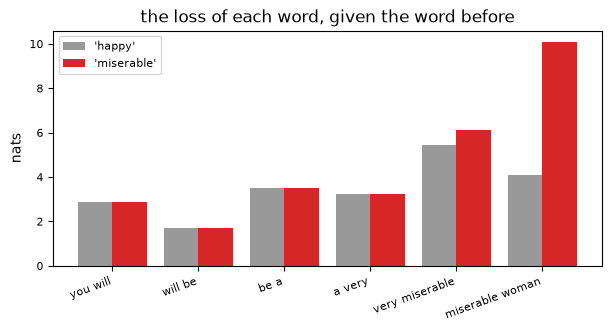

1.1197807981997403

In [2]:
WORD = "miserable"
swap(WORD)

### Solution

In [3]:
changes = {w: (sum(terms(SENTENCE[:5] + [w] + SENTENCE[6:])) - sum(terms(SENTENCE))) / 6 for w in ("miserable", "rich", "sensible")}
display(Markdown(f"Miserable raises the average loss by {changes['miserable']:.4f} nats and rich by {changes['rich']:.4f}: the "
                 f"bigram saw each once after very and never before woman, and their overall counts, {uni['miserable']} and "
                 f"{uni['rich']}, are close, so the two changes almost agree while the meanings are opposite. Sensible lowers the "
                 f"loss by {-changes['sensible']:.3f}: the bigram prefers a very sensible woman to the sentence Austen wrote."))

Miserable raises the average loss by 1.1198 nats and rich by 1.1196: the bigram saw each once after very and never before woman, and their overall counts, 6 and 8, are close, so the two changes almost agree while the meanings are opposite. Sensible lowers the loss by 0.179: the bigram prefers a very sensible woman to the sentence Austen wrote.

## 2. The bigram as a judge

Cut chapters 52 to 61 into windows of `K` words and pair each window with
the same words in reverse order. Take the bigram's total log-probability of
a window as its reward. Bradley-Terry turns the difference of two rewards
into the probability that a reader prefers the first. Run the cell for
windows of 10 words. Then set `K` to 3: how often does the original order
win now?

2,200 windows of 10 words: the original order wins 98.05 per cent; mean Bradley-Terry probability 0.9797


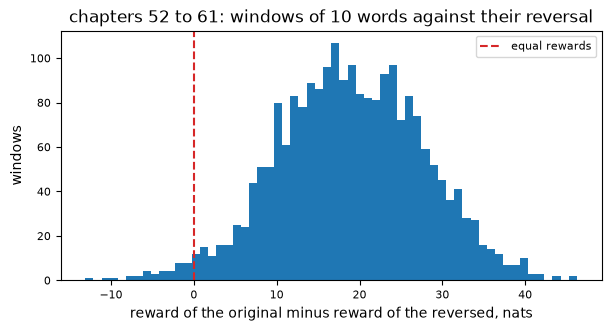

(0.9804545454545455, 0.9797372641227534)

In [4]:
K = 10
show_judge(K)

### Solution

In [5]:
gaps = {k: judge(k) for k in (10, 3)}
(ten, n10), (three, n3) = [(sum(g > 0 for g in gaps[k]) / len(gaps[k]), len(gaps[k])) for k in (10, 3)]
display(Markdown(f"In {n10:,} windows of 10 words the original order wins {100 * ten:.2f} per cent; in {n3:,} windows of 3 words, "
                 f"{100 * three:.2f} per cent, and the reversal scores at least as high in the other {100 - 100 * three:.2f}. Adding the same "
                 f"constant to every reward leaves each difference, and so each probability, as it was."))

In 2,200 windows of 10 words the original order wins 98.05 per cent; in 7,349 windows of 3 words, 79.96 per cent, and the reversal scores at least as high in the other 20.04. Adding the same constant to every reward leaves each difference, and so each probability, as it was.

## 3. A reward on the next word

After the word very, the bigram gives every word of chapters 1 to 51 a
probability. A reward of 1 on glad, happy, agreeable and pleasant, and 0 on
every other word, moves the KL optimum toward them: each probability is
multiplied by e to the power of the reward over beta, and the products are
divided by their sum. Run the cell for `BETA` 1. Then set `BETA` to 0.25:
what share do the four words take, and how far has the policy moved?

after 'very', beta 1: the rewarded words hold 0.0946 of the probability against 0.0370 under the bigram; KL divergence 0.0329 nats


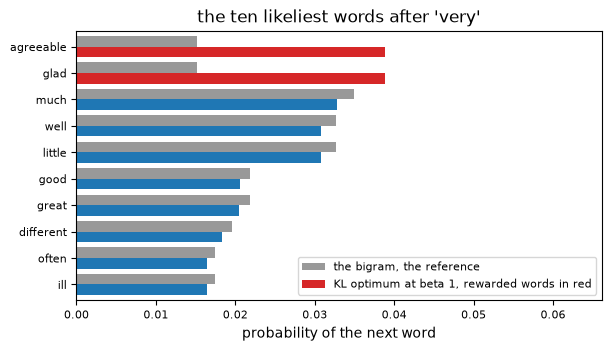

In [6]:
REWARDED = ("glad", "happy", "agreeable", "pleasant")
BETA = 1
show_reweight("very", REWARDED, BETA)

### Solution

In [7]:
(_, _, base, one, kl1), (_, _, _, quarter, kl4) = reweight("very", REWARDED, 1), reweight("very", REWARDED, 0.25)
display(Markdown(f"Under the bigram the four words hold {base:.4f} of the probability after very. At beta 1 they hold {one:.4f}, "
                 f"a KL divergence of {kl1:.4f} nats; at beta 0.25, {quarter:.4f}, at {kl4:.3f} nats. A smaller beta buys a "
                 f"larger share with a larger move away from the bigram."))

Under the bigram the four words hold 0.0370 of the probability after very. At beta 1 they hold 0.0946, a KL divergence of 0.0329 nats; at beta 0.25, 0.6772, at 1.616 nats. A smaller beta buys a larger share with a larger move away from the bigram.

## Appendix. The share and the KL divergence as beta grows

The cell repeats step 3 for beta from 0.05 to 20 and plots the share of the
rewarded words beside the KL divergence of the optimum from the bigram.

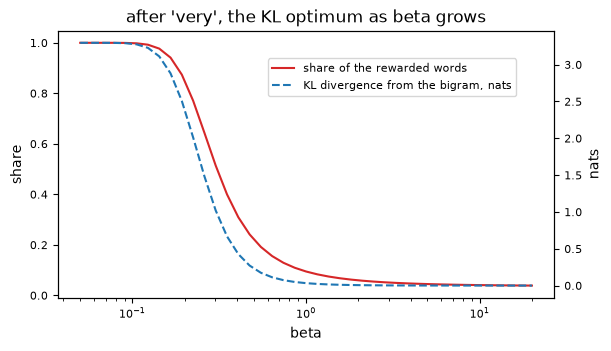

In [8]:
sweep("very", REWARDED)

**Exercise.** Set `CONTEXT` to "so": what share do the four words hold
under the bigram, and what share at `BETA` 0.25?

after 'very', beta 0.25: the rewarded words hold 0.6772 of the probability against 0.0370 under the bigram; KL divergence 1.6158 nats


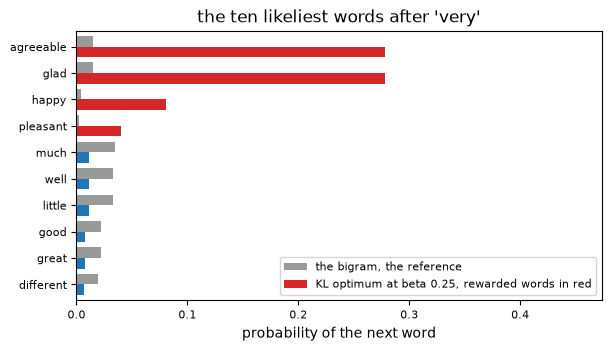

In [9]:
CONTEXT = "very"
BETA = 0.25
show_reweight(CONTEXT, REWARDED, BETA)

### Solution

In [10]:
(_, _, v0, v1, _), (_, _, s0, s1, _) = reweight("very", REWARDED, 0.25), reweight("so", REWARDED, 0.25)
display(Markdown(f"After very the four words hold {v0:.4f} under the bigram and {v1:.4f} at beta 0.25; after so, {s0:.4f} and "
                 f"{s1:.4f}. The reward multiplies the probability of every rewarded word by the same factor, so the share it "
                 f"reaches depends on the share the bigram starts from."))

After very the four words hold 0.0370 under the bigram and 0.6772 at beta 0.25; after so, 0.0155 and 0.4626. The reward multiplies the probability of every rewarded word by the same factor, so the share it reaches depends on the share the bigram starts from.